# MERGE — perguntas 2 e 3

Neste notebook descrevemos os dados e exploramos relações entre as variáveis e o quadrante. O conjunto de teste fica reservado para a avaliação final; a única consulta é a verificação de artistas partilhados na secção 3.5, sem usar os rótulos do teste.

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_dir = Path.cwd() / "dataset" / "build" / "MERGE_ECAC" / "merge_ecac"
media_dir = Path.cwd() / "dataset"
metadata = pd.read_csv(data_dir / "megtadata.csv")
av_values = pd.read_csv(data_dir / "av_values.csv")
test_ids = set(pd.read_csv(data_dir / "test_songs.csv")["Audio_Song"])
if not test_ids.issubset(set(metadata["Audio_Song"])):
    raise ValueError("Há músicas de teste ausentes de metadata.csv.")

test_mask = metadata["Audio_Song"].isin(test_ids)
development = metadata.loc[~test_mask].copy().reset_index(drop=True)
test = metadata.loc[test_mask].copy().reset_index(drop=True)

print(f"Metadata: {len(metadata)} linhas | desenvolvimento: {len(development)} | teste: {test['Audio_Song'].nunique()} músicas únicas")
print("Quadrantes no desenvolvimento:")
display(development["Quadrant"].value_counts().sort_index().to_frame("número de linhas"))

Metadata: 1348 linhas | desenvolvimento: 932 | teste: 409 músicas únicas
Quadrantes no desenvolvimento:


,número de linhas
Quadrant,
Q1,374
Q2,112
Q3,356
Q4,90


**Interpretação:** separámos primeiro as músicas de teste. As restantes contagens usam apenas o conjunto de desenvolvimento, mantendo no mesmo conjunto as linhas repetidas de cada música.

## 2. Compreensão dos dados

### 2.1 Colunas

A tabela resume o tipo, os valores em falta e os valores distintos de cada coluna. As descrições seguem o dicionário de dados.

In [12]:
meaning = {
    "Audio_Song": "ID do áudio", "Lyric_Song": "ID da letra", "Quadrant": "alvo",
    "AllMusic Id": "ID AllMusic", "AllMusic Extraction Date": "data da recolha",
    "Artist": "artista", "Title": "título", "Relevance": "relevância AllMusic",
    "Year": "data AllMusic", "LowestYear": "data mais antiga", "Duration": "duração (s)",
    "Moods": "etiquetas de humor", "MoodsAll": "etiquetas de humor completas",
    "MoodsAllWeights": "pesos de MoodsAll", "Genres": "géneros", "GenreWeights": "pesos de Genres",
    "Themes": "temas", "ThemeWeights": "pesos de Themes", "Styles": "estilos",
    "StyleWeights": "pesos de Styles", "AppearancesTrackIDs": "IDs de outras edições",
    "AppearancesAlbumIDs": "IDs dos álbuns", "Sample": "amostra disponível?",
    "SampleURL": "endereço da amostra", "ActualYear": "ano usado pelos autores",
    "num_Genres": "número de géneros", "num_MoodsAll": "número de etiquetas de humor",
}

summary = pd.DataFrame({
    "significado": pd.Series(meaning),
    "tipo": development.dtypes.astype(str),
    "em falta (%)": (development.isna().mean() * 100).round(1),
    "distintos": development.nunique(),
})
display(summary)

,significado,tipo,em falta (%),distintos
Audio_Song,ID do áudio,str,0.0,914
Lyric_Song,ID da letra,str,0.0,914
Quadrant,alvo,str,0.0,4
AllMusic Id,ID AllMusic,str,0.0,911
AllMusic Extraction Date,data da recolha,str,0.0,2
Artist,artista,str,0.0,655
Title,título,str,0.0,898
Relevance,relevância AllMusic,float64,17.2,757
Year,data AllMusic,str,12.4,487
LowestYear,data mais antiga,str,34.5,371


**Interpretação:** os IDs ligam os registos e `Quadrant` é a classe que queremos prever. As etiquetas e os respetivos pesos descrevem cada música; as datas de recolha e a disponibilidade de amostras são informação administrativa.

### 2.2 Cruzamento das fontes

O ficheiro `av_values.csv` contém `Arousal` e `Valence` e é ligado à tabela principal pelos IDs da música. O dicionário indica que cada música deve ter áudio e letra; as capas são opcionais. Como as pastas estão organizadas por quadrante, o caminho dos ficheiros revela a classe.

In [13]:
keys = ["Audio_Song", "Lyric_Song"]
joined = development.merge(av_values, on=keys, how="left", validate="many_to_one", indicator=True)
print(f"Pares únicos em metadata: {development[keys].drop_duplicates().shape[0]}")
print(f"Pares encontrados em av_values: {joined[keys + ['Arousal', 'Valence']].drop_duplicates().shape[0]}")
print(f"Linhas repetidas em metadata: {development.duplicated(keys).sum()}")
print(f"Linhas sem correspondência em av_values: {(joined['_merge'] != 'both').sum()}")

media = []
for label, folder, column, extension in [
    ("áudio", "audio", "Audio_Song", ".mp3"),
    ("letras", "lyrics", "Lyric_Song", ".txt"),
    ("capas", "album_covers", "Audio_Song", ".jpg"),
]:
    paths = [p for p in (media_dir / folder).rglob(f"*{extension}") if p.is_file() and not p.name.startswith("._")]
    file_quadrant = {p.stem: p.parent.name for p in paths}
    songs = development[[column, "Quadrant"]].drop_duplicates()
    present = songs[column].isin(file_quadrant)
    wrong = sum(file_quadrant.get(row[column]) != row["Quadrant"] for _, row in songs.loc[present].iterrows())
    media.append({"fonte": label, "com ficheiro": int(present.sum()), "sem ficheiro": int((~present).sum()), "pasta com quadrante errado": wrong})
display(pd.DataFrame(media))

Pares únicos em metadata: 914
Pares encontrados em av_values: 914
Linhas repetidas em metadata: 18
Linhas sem correspondência em av_values: 0


,fonte,com ficheiro,sem ficheiro,pasta com quadrante errado
0,áudio,914,0,0
1,letras,914,0,0
2,capas,825,89,0


**Interpretação:** há linhas repetidas na tabela principal, por isso várias linhas podem corresponder à mesma música em `av_values`. O áudio e as letras existem para todas as músicas analisadas; faltam algumas capas. Os ficheiros encontrados estão na pasta do quadrante indicado, mas não devemos usar essa pasta como preditor, porque ela revela a resposta.

### 2.3 Variáveis que podem revelar a resposta

- `Quadrant` é a classe que queremos prever, por isso não pode ser usado como variável de entrada.
- `Arousal` e `Valence` definem o quadrante através do limite 0,5 e também revelam diretamente a resposta.
- As pastas de áudio, letras e capas estão organizadas por quadrante; os respetivos caminhos também revelam a classe.

Os IDs identificam músicas e ficheiros. A documentação não indica que o seu conteúdo codifique o quadrante.

## 3. Análise exploratória

### 3.1–3.2 Distribuições, valores em falta e valores suspeitos

In [14]:
missing = development.isna().mean().mul(100).round(1).sort_values(ascending=False)
print("Ausências por coluna (%):")
display(missing.to_frame("em falta (%)"))
print("Colunas quase vazias (>= 90%):", missing[missing >= 90].index.tolist())
constant = [c for c in development if development[c].nunique(dropna=True) <= 1]
print("Colunas constantes:", constant if constant else "nenhuma")

for column in ["Relevance", "Duration", "Sample", "ActualYear", "num_Genres", "num_MoodsAll"]:
    values = pd.to_numeric(development[column], errors="coerce")
    print(f"{column}: mín. {values.min():g}, mediana {values.median():g}, máx. {values.max():g}")

for column in ["Year", "LowestYear"]:
    print(f"\nValores mais frequentes em {column}:")
    display(development[column].value_counts(dropna=False).head(5).to_frame("frequência"))

Ausências por coluna (%):


,em falta (%)
num_MoodsAll,98.9
num_Genres,98.9
LowestYear,34.5
ActualYear,22.7
Duration,20.4
Relevance,17.2
ThemeWeights,16.2
Themes,16.2
Genres,13.5
Year,12.4


Colunas quase vazias (>= 90%): ['num_MoodsAll', 'num_Genres']
Colunas constantes: nenhuma
Relevance: mín. 1.01027, mediana 1.03932, máx. 1.84
Duration: mín. -1, mediana 197, máx. 367000
Sample: mín. 0, mediana 1, máx. 1
ActualYear: mín. 0, mediana 1997, máx. 9999
num_Genres: mín. 0, mediana 1, máx. 2
num_MoodsAll: mín. 0, mediana 12.5, máx. 23

Valores mais frequentes em Year:


,frequência
Year,
NaN,116
1983-??-??,10
1997-??-??,8
1958-??-??,8
1989-??-??,8



Valores mais frequentes em LowestYear:


,frequência
LowestYear,
NaN,322
1994-??-??,8
1993-??-??,7
1986-??-??,7
1983-??-??,7


**Interpretação:** `Duration` tem valores negativos, apesar de o dicionário indicar que a duração deve ser positiva. Também surgem durações e anos extremos que convém verificar na etapa de limpeza. As colunas quase vazias fornecem pouca informação nesta análise. Por agora, apenas identificamos estes casos: não alteramos os dados.

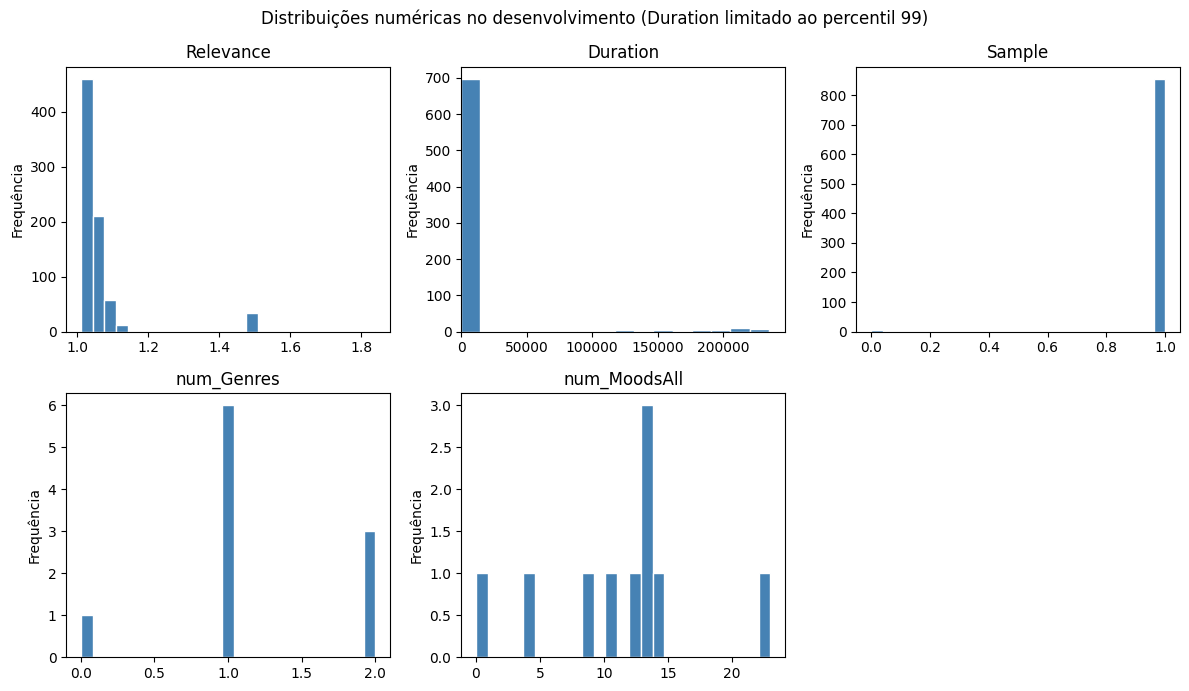

In [15]:
numeric = development.select_dtypes(include="number").columns.tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, column in zip(axes.flat, numeric):
    values = development[column].dropna()
    ax.hist(values, bins=25, color="steelblue", edgecolor="white")
    ax.set(title=column, ylabel="Frequência")
    if column == "Duration" and len(values):
        ax.set_xlim(min(0, values.min()), values.quantile(0.99))
for ax in axes.flat[len(numeric):]:
    ax.set_visible(False)
fig.suptitle("Distribuições numéricas no desenvolvimento (Duration limitado ao percentil 99)")
fig.tight_layout()
plt.show()

**Interpretação:** os histogramas mostram como se distribuem os valores numéricos. No gráfico de `Duration`, o eixo está limitado ao percentil 99 para facilitar a leitura; os valores acima desse limite continuam nos dados e serão investigados.

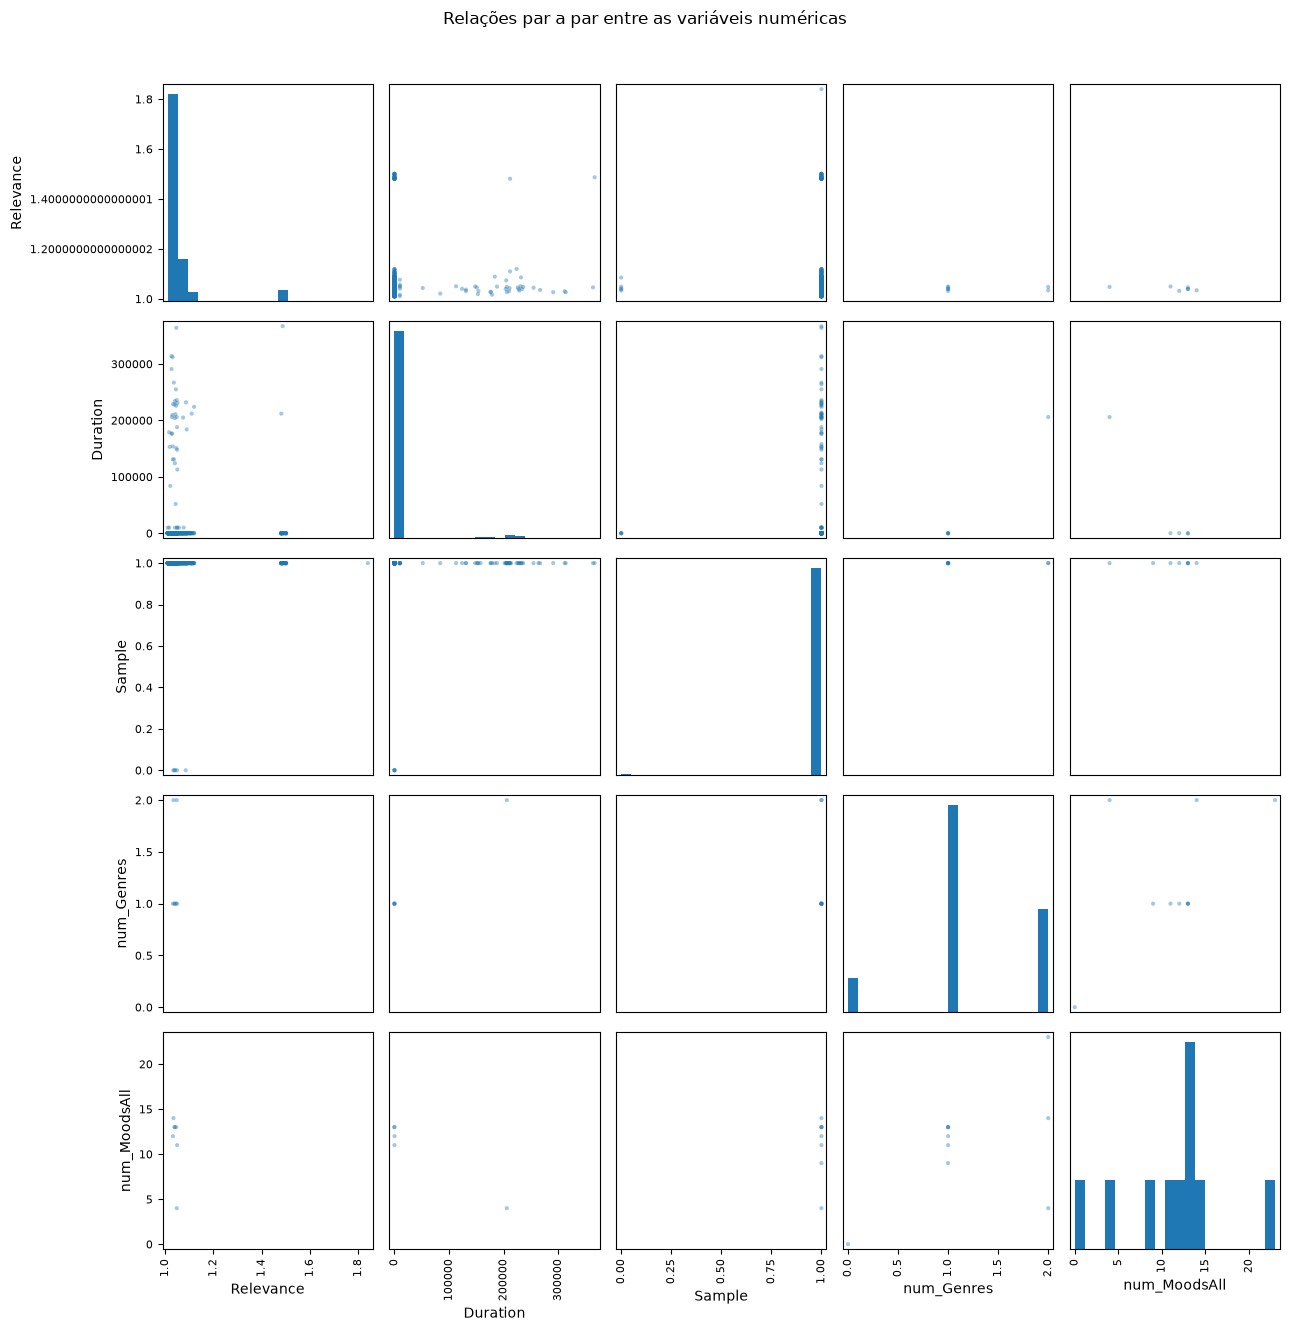

In [3]:
numeric = development.select_dtypes(include="number").columns.tolist()
fig = pd.plotting.scatter_matrix(
    development[numeric],
    figsize=(13, 13),
    diagonal="hist",
    alpha=0.4,
    marker=".",
    hist_kwds={"bins": 20},
)
plt.suptitle("Relações par a par entre as variáveis numéricas", y=1.02)
plt.tight_layout()
plt.show()

**Interpretação:** cada painel compara duas variáveis numéricas e a diagonal mostra a distribuição de cada uma. Os valores em falta não foram preenchidos. As colunas quase vazias e os valores extremos dificultam a leitura, por isso estas relações devem ser vistas como uma primeira exploração.

### 3.3–3.4 Relação entre cada coluna e o quadrante

Para comparar as colunas, dividimos o conjunto de desenvolvimento em cinco partes e, em cada ronda, prevemos a classe mais frequente para cada valor (ou intervalo numérico). Usamos macro-F1, que dá o mesmo peso às quatro classes, e comparamos o resultado com uma previsão de referência baseada na classe mais frequente. As linhas da mesma música ficam sempre na mesma parte. É uma comparação inicial de cada coluna, não substitui o modelo k-NN do projeto.

In [16]:
classes = ["Q1", "Q2", "Q3", "Q4"]
songs = development[["Audio_Song", "Quadrant"]].drop_duplicates()
rng = np.random.default_rng(42)
fold_map = {}
for label in classes:
    ids = songs.loc[songs["Quadrant"] == label, "Audio_Song"].to_numpy().copy()
    rng.shuffle(ids)
    fold_map.update({song: i % 5 for i, song in enumerate(ids)})
fold = development["Audio_Song"].map(fold_map)

def keys_for(train, valid):
    x_train = pd.to_numeric(train, errors="coerce")
    x_valid = pd.to_numeric(valid, errors="coerce")
    if train.notna().sum() and x_train.notna().sum() / train.notna().sum() >= 0.95:
        edges = np.r_[-np.inf, x_train.dropna().quantile([.2, .4, .6, .8]).unique(), np.inf]
        a = pd.cut(x_train, edges, include_lowest=True).astype(str).where(x_train.notna(), "[em falta]")
        b = pd.cut(x_valid, edges, include_lowest=True).astype(str).where(x_valid.notna(), "[em falta]")
    else:
        a, b = train.fillna("[em falta]").astype(str), valid.fillna("[em falta]").astype(str)
    return a, b

def macro_f1(actual, predicted):
    values = []
    for label in classes:
        tp = ((actual == label) & (predicted == label)).sum()
        fp = ((actual != label) & (predicted == label)).sum()
        fn = ((actual == label) & (predicted != label)).sum()
        values.append(2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0)
    return np.mean(values)

features = joined.drop(columns=["Quadrant", "_merge"]).columns
results = []
for feature in features:
    prediction = pd.Series(index=joined.index, dtype="object")
    baseline = pd.Series(index=joined.index, dtype="object")
    for part in range(5):
        valid = fold == part
        train = ~valid
        train_key, valid_key = keys_for(joined.loc[train, feature], joined.loc[valid, feature])
        labels = joined.loc[train, "Quadrant"]
        majority = labels.value_counts().idxmax()
        lookup = pd.DataFrame({"key": train_key, "label": labels}).groupby("key")["label"].agg(lambda x: x.value_counts().idxmax())
        prediction.loc[valid] = valid_key.map(lookup).fillna(majority)
        baseline.loc[valid] = majority
    actual = joined["Quadrant"]
    results.append({
        "coluna": feature,
        "accuracy": (prediction == actual).mean(),
        "macro-F1": macro_f1(actual, prediction),
        "macro-F1 referência": macro_f1(actual, baseline),
    })

results = pd.DataFrame(results).sort_values("macro-F1", ascending=False).reset_index(drop=True)
display(results.round(3))
suspects = results[results["coluna"].isin(["Arousal", "Valence"])]
reference = results["macro-F1 referência"].mean()
print(f"Suspeitas Arousal/Valence acima da referência: {(suspects['macro-F1'] > reference).sum()} de {len(suspects)}.")

,coluna,accuracy,macro-F1,macro-F1 referência
0,Genres,0.591,0.497,0.143
1,Styles,0.578,0.495,0.143
2,Arousal,0.721,0.494,0.143
3,Artist,0.535,0.447,0.143
4,Valence,0.723,0.407,0.143
5,Moods,0.533,0.396,0.143
6,Themes,0.541,0.388,0.143
7,Year,0.484,0.381,0.143
8,MoodsAll,0.488,0.337,0.143
9,StyleWeights,0.464,0.336,0.143


Suspeitas Arousal/Valence acima da referência: 2 de 2.


**Interpretação:** as colunas no topo têm maior associação com o quadrante nesta comparação. `Arousal` e `Valence` não devem entrar no modelo, porque são usadas para definir a própria classe. Nas outras colunas, uma associação elevada não prova, por si só, fuga de informação nem uma relação de causa.

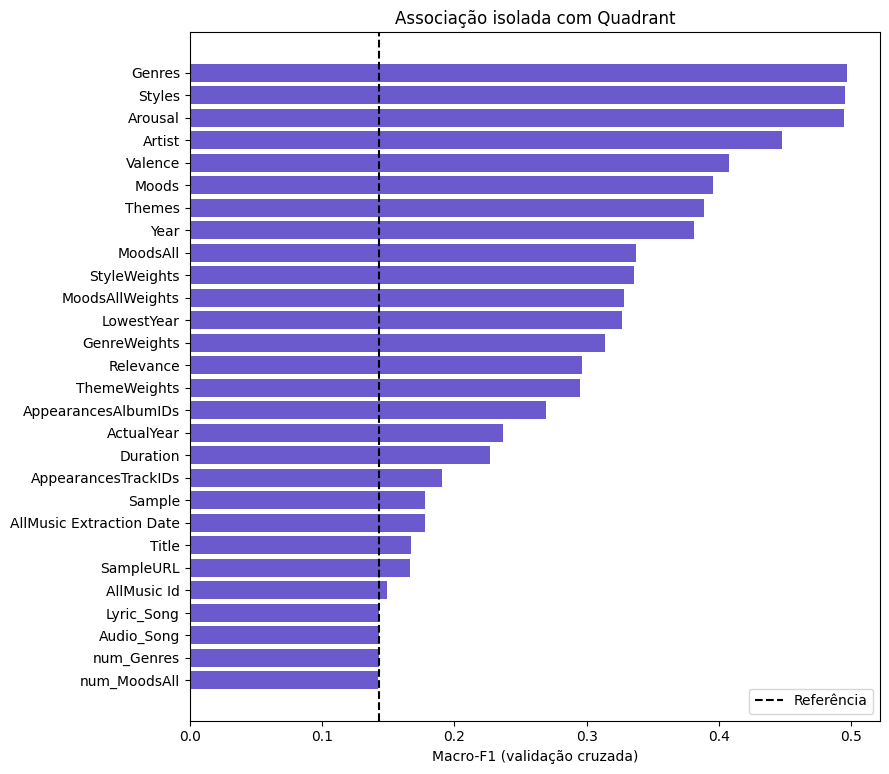

In [17]:
plot = results.sort_values("macro-F1")
fig, ax = plt.subplots(figsize=(9, max(6, len(plot) * 0.28)))
ax.barh(plot["coluna"], plot["macro-F1"], color="slateblue")
ax.axvline(reference, color="black", linestyle="--", label="Referência")
ax.set(xlabel="Macro-F1 (validação cruzada)", title="Associação isolada com Quadrant")
ax.legend()
fig.tight_layout()
plt.show()

**Interpretação:** o gráfico ordena as colunas pela pontuação macro-F1 e mostra a linha de referência. Os valores exatos estão na tabela anterior. As variáveis que podem revelar a resposta foram identificadas antes desta comparação.

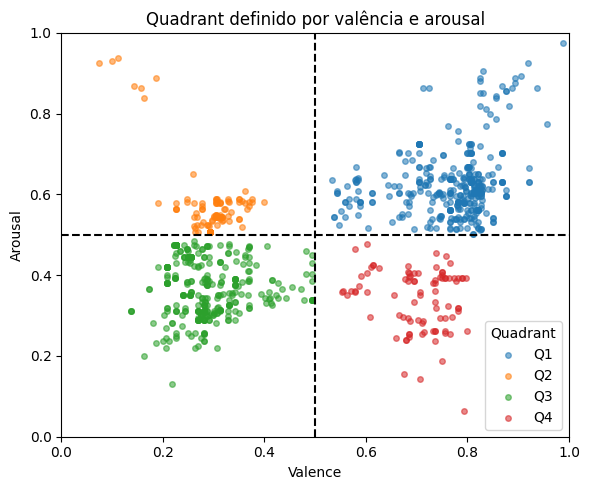

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
for label, group in joined.groupby("Quadrant"):
    ax.scatter(group["Valence"], group["Arousal"], s=16, alpha=.55, label=label)
ax.axvline(.5, color="black", linestyle="--")
ax.axhline(.5, color="black", linestyle="--")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Valence", ylabel="Arousal", title="Quadrant definido por valência e arousal")
ax.legend(title="Quadrant")
fig.tight_layout()
plt.show()

**Interpretação:** as linhas tracejadas mostram os limites de 0,5 usados para formar os quadrantes. Como `Valence` e `Arousal` determinam a classe, não devem ser usadas para a prever.

### 3.5 Artistas que aparecem no desenvolvimento e no teste

In [19]:
development_artists = set(development["Artist"].dropna())
test_songs = test.drop_duplicates("Audio_Song")
shared = test_songs["Artist"].isin(development_artists)
print(f"Músicas de teste com artista (mesma grafia) no desenvolvimento: {shared.sum()} de {len(test_songs)}.")
print(f"Artistas distintos partilhados: {test_songs.loc[shared, 'Artist'].nunique()}.")

Músicas de teste com artista (mesma grafia) no desenvolvimento: 200 de 409.
Artistas distintos partilhados: 104.


**Interpretação:** esta contagem compara os nomes dos artistas tal como estão escritos; diferenças de grafia podem esconder correspondências. É uma verificação de possível sobreposição entre desenvolvimento e teste, pedida no enunciado. Não usa os rótulos do teste nem mede o desempenho de um modelo.

## Conclusão

A análise descreve as colunas, os valores em falta, a cobertura dos ficheiros e a relação inicial entre cada variável e o quadrante. Encontrámos valores que precisam de ser investigados, além de variáveis que revelam diretamente a classe e não devem ser usadas como preditores. Os dados não foram alterados. O teste só foi consultado para verificar a partilha de artistas; a avaliação do modelo fica para a secção 14.